In [1]:
# ==========================================
# CELL 1: Setup & Load Final Data
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/movies_final.csv")

# We focus our analysis on the modern blockbuster era (1990 onwards)
df90 = df[df['release_year'] >= 1990].copy()

The Trend Over Time

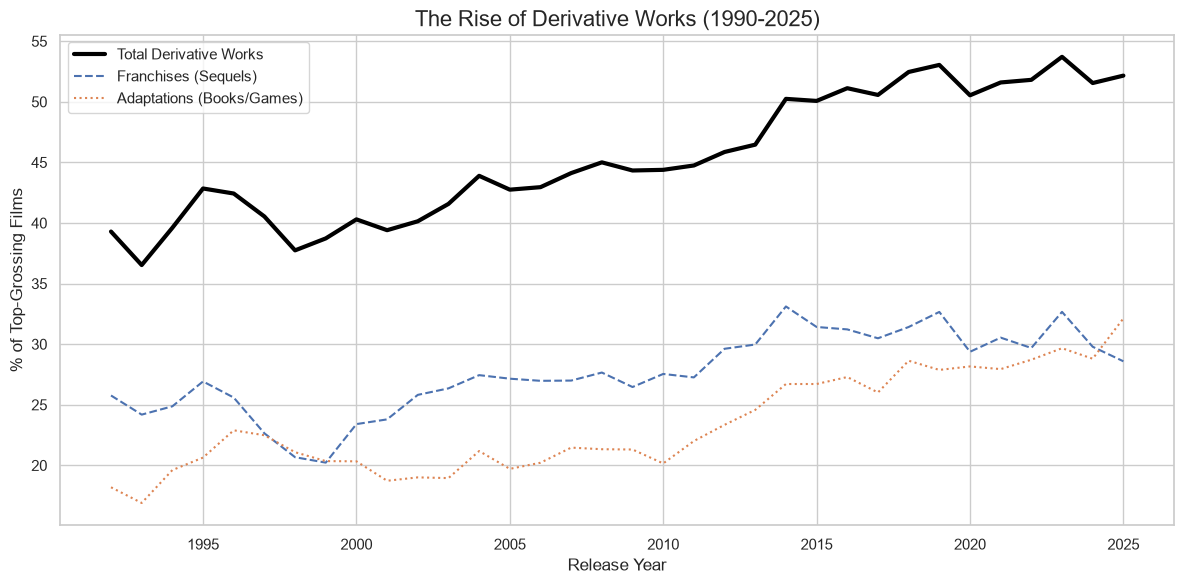

In [2]:
# Calculate the % of derivative works by year
yearly = df90.groupby("release_year")[["is_derivative", "is_franchise", "is_adaptation"]].mean() * 100

# Smooth it out with a 3-year rolling average to see the trend clearly
yearly_smooth = yearly.rolling(window=3).mean()

plt.figure(figsize=(12, 6))
plt.plot(yearly_smooth.index, yearly_smooth["is_derivative"], label="Total Derivative Works", linewidth=3, color="black")
plt.plot(yearly_smooth.index, yearly_smooth["is_franchise"], label="Franchises (Sequels)", linestyle="--")
plt.plot(yearly_smooth.index, yearly_smooth["is_adaptation"], label="Adaptations (Books/Games)", linestyle=":")

plt.title("The Rise of Derivative Works (1990-2025)", fontsize=16)
plt.ylabel("% of Top-Grossing Films", fontsize=12)
plt.xlabel("Release Year", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Financial Risk

C:\Users\nisri\AppData\Local\Temp\ipykernel_12080\3514992108.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df90, x="is_derivative", y="log_roi", palette="Set2")


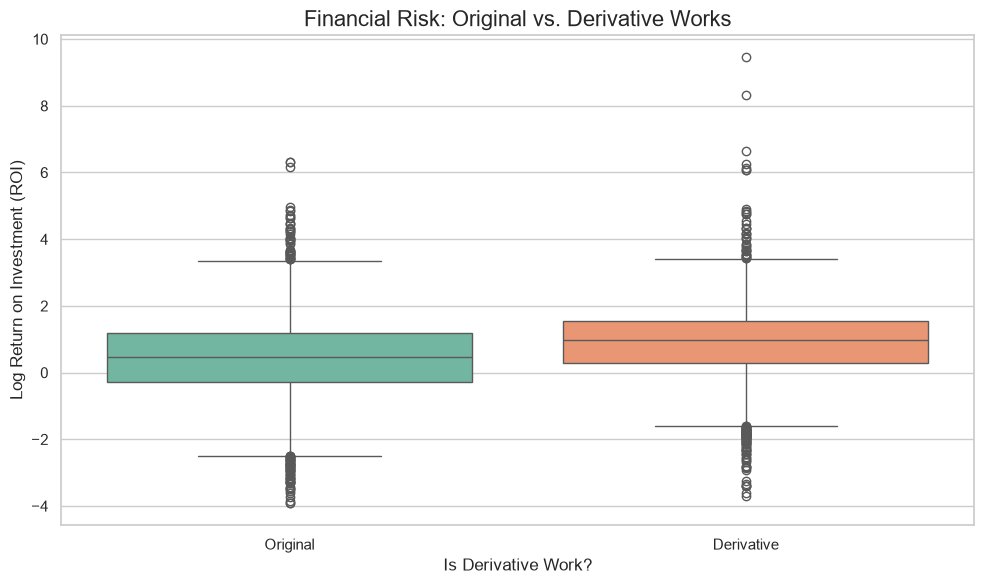

Median ROI:
is_derivative
False    1.615276
True     2.680105
Name: roi, dtype: float64

Failure Rate (ROI < 1, meaning it lost money):
is_derivative
False    33.393448
True     18.362989
Name: roi, dtype: float64


In [3]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df90, x="is_derivative", y="log_roi", palette="Set2")
plt.title("Financial Risk: Original vs. Derivative Works", fontsize=16)
plt.xlabel("Is Derivative Work?", fontsize=12)
plt.ylabel("Log Return on Investment (ROI)", fontsize=12)
plt.xticks([0, 1], ["Original", "Derivative"])
plt.tight_layout()
plt.show()

# Calculate the exact failure rates (ROI < 1 means it lost money)
print("Median ROI:")
print(df90.groupby("is_derivative")["roi"].median())

print("\nFailure Rate (ROI < 1, meaning it lost money):")
print(df90.groupby("is_derivative")["roi"].apply(lambda x: (x < 1).mean() * 100))

Revenue Concentration

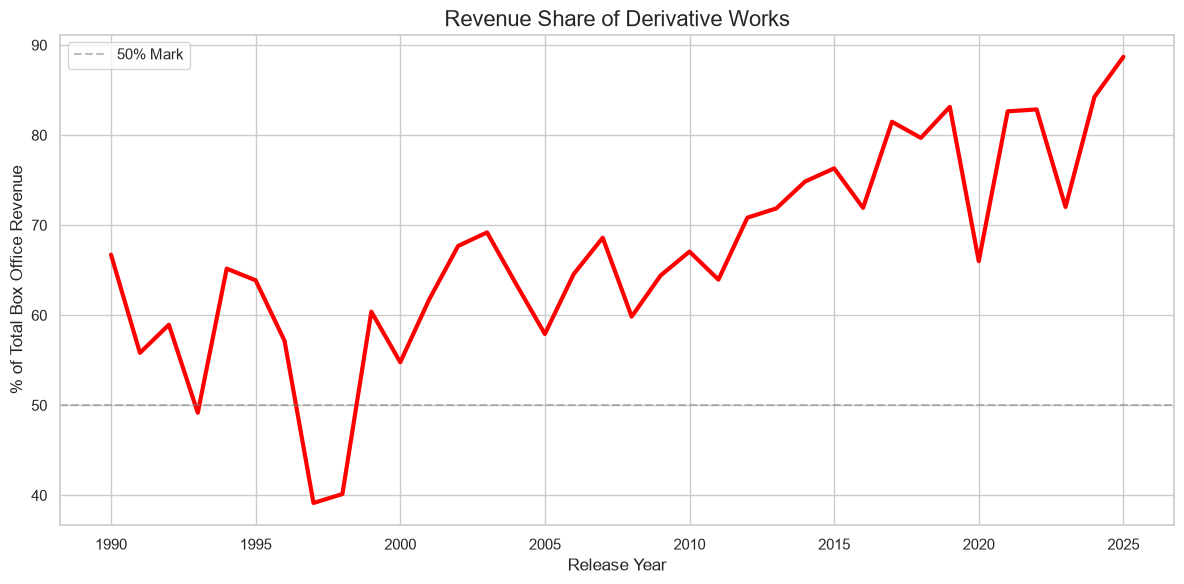

In [4]:
# Group by year and sum the revenue
rev_by_year = df90.groupby(["release_year", "is_derivative"])["revenue"].sum().unstack().fillna(0)

rev_by_year["Total"] = rev_by_year[False] + rev_by_year[True]
rev_by_year["Derivative_Share"] = (rev_by_year[True] / rev_by_year["Total"]) * 100

plt.figure(figsize=(12, 6))
plt.plot(rev_by_year.index, rev_by_year["Derivative_Share"], color="red", linewidth=3)
plt.axhline(y=50, color="gray", linestyle="--", alpha=0.5, label="50% Mark")

plt.title("Revenue Share of Derivative Works", fontsize=16)
plt.ylabel("% of Total Box Office Revenue", fontsize=12)
plt.xlabel("Release Year", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Genre & Studio Analysis

<Figure size 1200x600 with 0 Axes>

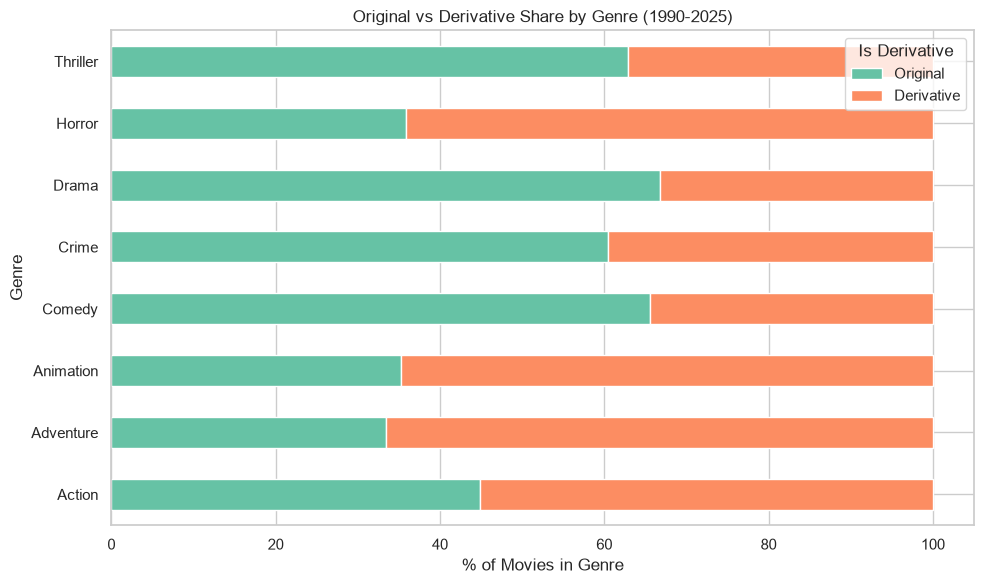

Top Studios by Volume:
                       total_movies  derivative_share  median_roi
studio                                                           
Paramount Pictures              207             51.21        1.91
Universal Pictures              206             53.88        2.22
Columbia Pictures               166             48.80        2.61
New Line Cinema                 138             47.83        2.19
Warner Bros. Pictures           125             62.40        2.15
Walt Disney Pictures            111             65.77        2.22
Touchstone Pictures              78             25.64        2.17
20th Century Fox                 71             57.75        2.93
Miramax                          64             31.25        1.58
DreamWorks Pictures              53             41.51        2.17
Lionsgate                        50             68.00        2.25
TriStar Pictures                 50             28.00        1.82
Metro-Goldwyn-Mayer              44             61.36

In [5]:
# 1. Genre Analysis
top_genres = df90["primary_genre"].value_counts().head(8).index
genre_df = df90[df90["primary_genre"].isin(top_genres)]

plt.figure(figsize=(12, 6))
genre_derivative = pd.crosstab(genre_df["primary_genre"], genre_df["is_derivative"], normalize="index") * 100
genre_derivative.plot(kind="barh", stacked=True, color=["#66c2a5", "#fc8d62"], figsize=(10, 6))

plt.title("Original vs Derivative Share by Genre (1990-2025)")
plt.xlabel("% of Movies in Genre")
plt.ylabel("Genre")
plt.legend(title="Is Derivative", labels=["Original", "Derivative"])
plt.tight_layout()
plt.show()

# 2. Studio Analysis (Requires reloading raw data for production companies)
import json
import glob

RAW_DIR = "../data"
files = glob.glob(f"{RAW_DIR}/*.jsonl")
studios_dict = {}

for f in files:
    with open(f, "r", encoding="utf-8") as file:
        for line in file:
            movie = json.loads(line)
            if movie.get("production_companies"):
                studios_dict[movie["id"]] = movie["production_companies"][0]["name"]
            else:
                studios_dict[movie["id"]] = "Unknown"

df90["studio"] = df90["id"].map(studios_dict)

top_studios = df90["studio"].value_counts().head(15).index
studio_stats = df90[df90["studio"].isin(top_studios)].groupby("studio").agg(
    total_movies=("id", "count"),
    derivative_share=("is_derivative", lambda x: x.mean() * 100),
    median_roi=("roi", "median")
).sort_values("total_movies", ascending=False)

print("Top Studios by Volume:")
print(studio_stats.round(2))